In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
import rebound

/Users/haydenmonk/mambaforge/envs/comets/lib/python3.11/site-packages/rebound/simulation.py:148: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)


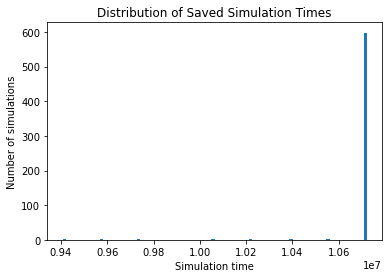

In [14]:


folder = Path("/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Sim_Archives_Restarted/2215154/2215154_mass_7.94328235e-05")

sim_times = []

for file in folder.glob("*.bin"):
    try:
        sim = rebound.Simulation(str(file))
        p=sim.particles[0]
        # r=np.sqrt(p.x*p.x+p.y*p.y+p.z*p.z)
        # v_2=p.vx**2+p.vy**2+p.vz**2
        # inv_a=2/r-v_2/(39.478)
        # sim_times.append(inv_a)
        sim_times.append(sim.t)
        

    except Exception as e:
        print(f"Could not load {file.name}: {e}")

plt.hist(sim_times, bins=90)

plt.xlabel("Simulation time")
plt.ylabel("Number of simulations")
plt.title("Distribution of Saved Simulation Times")
#plt.yscale("log")   
#plt.hlines(300,0,8e6)

plt.show()

In [13]:
(2.02731513e+01*(10**-4.1)**(-3/2) + 6.97903308e+04)

28706377.68986756

In [87]:
sim=rebound.Simulation('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Sim_Archives/2199100_mass_1.00000000e-05/particle_774.bin')

/Users/haydenmonk/mambaforge/envs/comets/lib/python3.11/site-packages/rebound/simulation.py:148: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)


In [84]:
p=sim.particles[0]
print(np.sqrt(p.x**2+p.y**2+p.z**2))
print(p.vx)
print(p.vy)
print(p.vz)
print(sim.t)

0.48845340118292746
0.053381481343214056
-10.381764465498174
-0.6525642280732964
388998.05501458736


In [ ]:
"""Diagnose one archived massless REBOUND particle with the original C gravity."""
from ctypes import CDLL, c_double
from pathlib import Path
import warnings
import rebound

ROOT = Path('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction')

# EDIT THESE TWO VALUES. Mass must match the archive directory's mass.
ARCHIVE_FILE = '/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Sim_Archives/2199100_mass_1.00000000e-05/particle_410.bin'
M_PLANET = 1e-5  # Msun

HEARTBEAT_LIB = ROOT / 'Inputs/N_Body_Scripts/Heartbeat/heartbeat.so'
A_PLANET = 1.0  # AU
M_STAR = 1.0    # Msun
BACKWARD_YEARS = 100.0
FORWARD_YEARS = 200.0  # relative to original archive time

# Load the archive, not a copy that has already been integrated.
sim = rebound.Simulation(str(ARCHIVE_FILE))
if sim.N != 1:
    raise ValueError(f'Expected one massless particle, got {sim.N}')


clib = CDLL(str(HEARTBEAT_LIB))
clib.setup_force.argtypes = [c_double] * 10
clib.setup_force.restype = None
# Exactly the same setup parameters as restart_mass_fraction.py.
clib.setup_force(A_PLANET, 0.0, 0.0, 0.0, 0.0, 0.0,
                 0.0, M_PLANET, M_STAR, sim.G)
sim.additional_forces = clib.planet_star_force

original_time = sim.t
print(f'Loaded: {ARCHIVE_FILE}', flush=True)
print(f'Initial t={sim.t:.12g}, dt={sim.dt:.12g}, G={sim.G:.12g}', flush=True)

# REBOUND may preserve a saved adaptive timestep; IAS15 controls internal steps.
# Set exact_finish_time=True by default, as in sim.integrate(t).
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always', RuntimeWarning)
    for label, target in [
        ('backward', original_time - BACKWARD_YEARS),
        ('forward', original_time + FORWARD_YEARS),
    ]:
        print(f'Integrating {label}: t={sim.t:.12g} -> {target:.12g}', flush=True)
        sim.integrate(target)
        p = sim.particles[0]
        print(f'  reached t={sim.t:.12g}, dt={sim.dt:.12g}; '
              f'particle xyz=({p.x:.8g}, {p.y:.8g}, {p.z:.8g})', flush=True)
    for warning in caught:
        print(f'WARNING: {warning.message}', flush=True)
print('Finished.', flush=True)


Loaded: /Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Sim_Archives/2199100_mass_1.00000000e-05/particle_410.bin
Initial t=1732991.33506, dt=0.0135079464731, G=39.4769264214
Integrating backward: t=1732991.33506 -> 1732891.33506
  reached t=1732891.33506, dt=-0.03458302335; particle xyz=(-0.89934789, 0.40287466, -0.16060052)
Integrating forward: t=1732891.33506 -> 1733191.33506


/Users/haydenmonk/mambaforge/envs/comets/lib/python3.11/site-packages/rebound/simulation.py:148: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)


  reached t=1733191.33506, dt=0.0145176384434; particle xyz=(-0.16115082, 0.7694912, -0.091621463)
Finished.


In [261]:
sa = rebound.Simulationarchive(ARCHIVE_FILE)

print("Number of snapshots:", len(sa))

# Load the second most recent snapshot
sim = sa[-2]
sim.additional_forces = clib.planet_star_force

print("Loaded time:", sim.t)

Number of snapshots: 18
Loaded time: 1640991.7950615368


In [262]:
sim.particles[0]

<rebound.particle.Particle object at 0x12d3da2d0, m=0.0 x=-0.8327386552255654 y=0.49951505560153653 z=-0.0022452364696949733 vx=-4.6583496988209365 vy=-5.1170341852361005 vz=0.8297275909407388>

In [263]:
import warnings
import numpy as np

planet_period = np.sqrt(A_PLANET**3 / (M_STAR + M_PLANET))
cadence = 1000 * planet_period


with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", RuntimeWarning)
    
    sim.integrate(1732995)

for warning in caught:
    if "predictor corrector loops" in str(warning.message):
        print(
            f"IAS15 WARNING: t={sim.t}, "
            f"dt={sim.dt}, target={target_t}",
            flush=True,
        )

In [264]:
sim.t

1732995.0

In [86]:
sim.integrate(389000)

In [26]:
max(sim_times)

0.0

In [50]:
from pathlib import Path
import rebound

folder = Path("/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Sim_Archives/2196199_mass_7.94328235e-05")
r_list=[]
for file in sorted(folder.glob("*.bin")):
    sa = rebound.Simulationarchive(str(file))
    sim=sa[-1]
    print(
        file.name,
        "snapshots =", len(sa),
        "t_first =", sa.tmin,
        "t_last =", sa.tmax,

        r_list.append(np.sqrt(sim.particles[0].x**2+sim.particles[0].y**2+sim.particles[0].z**2))
    )

/Users/haydenmonk/mambaforge/envs/comets/lib/python3.11/site-packages/rebound/simulationarchive.py:142: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)


particle_0.bin snapshots = 9 t_first = 0.0 t_last = 1607936.1398143491 None
particle_1.bin snapshots = 9 t_first = 0.0 t_last = 1607936.1398143491 None
particle_10.bin snapshots = 9 t_first = 0.0 t_last = 1607936.1398143491 None
particle_100.bin snapshots = 9 t_first = 0.0 t_last = 1607936.1398143491 None
particle_101.bin snapshots = 9 t_first = 0.0 t_last = 1607936.1398143491 None
particle_102.bin snapshots = 9 t_first = 0.0 t_last = 1607936.1398143491 None
particle_103.bin snapshots = 9 t_first = 0.0 t_last = 1607936.1398143491 None
particle_104.bin snapshots = 9 t_first = 0.0 t_last = 1607936.1398143491 None
particle_105.bin snapshots = 9 t_first = 0.0 t_last = 1607936.1398143491 None
particle_106.bin snapshots = 9 t_first = 0.0 t_last = 1607936.1398143491 None
particle_107.bin snapshots = 9 t_first = 0.0 t_last = 1607936.1398143491 None
particle_108.bin snapshots = 9 t_first = 0.0 t_last = 1607936.1398143491 None
particle_109.bin snapshots = 9 t_first = 0.0 t_last = 1607936.1398143

In [16]:
len(sim_times)
max(sim_times)

3536060.3560981066

In [21]:
nonzero_list=[time for time in sim_times if time > 0]

In [22]:
nonzero_list

[3205100.9981729817,
 3396452.8698160895,
 3155678.8160565486,
 3192850.692583365,
 3466784.2257003016,
 3112754.6994481143,
 3536060.3560981066,
 3421763.8027832173,
 2927185.021430224]

In [15]:
sim_times

[0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 3205100.9981729817,
 0.0,
 0.0,
 0.0,
 0.0,
 3396452.8698160895,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0

In [30]:
df_f=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/2186705_ejection_results.txt', header=None)
df_f.columns=['mass','time','result','particle_id']

In [34]:
df_f.mass.unique()

array([3.98107171e-05, 7.94328235e-05, 1.58489319e-04, 1.00000000e-05])

In [45]:
from pathlib import Path
import numpy as np
import rebound


m_planet = 1.25892541e-03
N_particles = 300

archive_root = Path(
    "/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Sim_Archives"
)


# ------------------------------------------------------------
# 1. Find first unejected particle
# ------------------------------------------------------------

ejected_ids = set(
    df_f.loc[
        np.isclose(df_f["mass"], m_planet)
        & (df_f["result"] == "Ejected"),
        "particle_id"
    ].astype(int)
)

unejected_ids = [
    pid
    for pid in range(N_particles)
    if pid not in ejected_ids
]
for pid in range(N_particles):
    archive_file = (
    archive_root
    / f"mass_1.58489319e-04"
    / f"particle_{pid}.bin"
    )


    sa = rebound.Simulationarchive(str(archive_file))
    if len(sa) >1 :
        sim=sa[0]
        print(sim.t)

particle_id = unejected_ids[0]
particle_id = 6

print("First unejected particle:", particle_id)


# ------------------------------------------------------------
# 2. Open its SimulationArchive
# ------------------------------------------------------------

archive_file = (
    archive_root
    / f"mass_1.58489319e-04"
    / f"particle_{particle_id}.bin"
)

sa = rebound.Simulationarchive(str(archive_file))

print("Archive:", archive_file)
print("Number of snapshots:", len(sa))


# ------------------------------------------------------------
# 3. Load last two snapshots
# ------------------------------------------------------------
sim_last = sa[len(sa) - 1]
print(sim_last.t)
if len(sa) < 2:
    raise RuntimeError(
        f"Particle {particle_id} only has {len(sa)} snapshot(s)."
    )

sim_prev = sa[len(sa) - 2]
sim_last = sa[len(sa) - 1]

print("\nPrevious snapshot:")
print("t =", sim_prev.t)

print("\nLatest snapshot:")
print("t =", sim_last.t)

print("\nSimulation-time advancement:")
print("Δt =", sim_last.t - sim_prev.t)


# ------------------------------------------------------------
# 4. Compare particle phase-space coordinates
# ------------------------------------------------------------

p_prev = sim_prev.particles[0]
p_last = sim_last.particles[0]

state_prev = np.array([
    p_prev.x, p_prev.y, p_prev.z,
    p_prev.vx, p_prev.vy, p_prev.vz
])

state_last = np.array([
    p_last.x, p_last.y, p_last.z,
    p_last.vx, p_last.vy, p_last.vz
])

print("\nPrevious state:")
print(state_prev)

print("\nLatest state:")
print(state_last)

print("\nChange in state:")
print(state_last - state_prev)

First unejected particle: 6
Archive: /Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Sim_Archives/mass_1.58489319e-04/particle_6.bin
Number of snapshots: 1
0.0


/Users/haydenmonk/mambaforge/envs/comets/lib/python3.11/site-packages/rebound/simulationarchive.py:142: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)


RuntimeError: Particle 6 only has 1 snapshot(s).